# Phân tích khám phá dữ liệu (EDA)

Notebook này phân tích bộ dữ liệu phân loại 10 loại trái cây. Mục tiêu là hiểu cấu trúc dữ liệu, phân bố số lượng ảnh, chất lượng ảnh, kích thước ảnh và nguy cơ rò rỉ dữ liệu trước khi tạo split để huấn luyện.

Notebook chỉ đọc dữ liệu trong `data/raw/`, không chỉnh sửa hoặc xóa ảnh gốc.

## 1. Chuẩn bị thư viện và đường dẫn

Sử dụng `Pillow` để đọc và kiểm tra ảnh, `pandas` để tổng hợp số liệu, `numpy` và `matplotlib` để phân tích và trực quan hóa. Đường dẫn được lấy từ thư mục gốc của project để notebook chạy được khi mở từ project root hoặc từ thư mục `notebooks`.

In [2]:
from pathlib import Path
import hashlib
import math

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image

ROOT = Path.cwd()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
RAW = ROOT / 'data' / 'raw'
IMAGE_EXTENSIONS = {'.jpg', '.jpeg', '.png', '.bmp', '.gif', '.webp'}
assert RAW.exists(), f'Raw data directory not found: {RAW}'

## 2. Thống kê số lượng ảnh và kiểm tra khả năng đọc

Với mỗi ảnh, ta lưu split, tên lớp, kích thước, mode màu, định dạng, tỉ lệ khung hình và mã băm SHA-256 của nội dung RGB. Việc mở ảnh rồi gọi `verify()` giúp phát hiện file bị hỏng; mã băm được dùng ở phần sau để tìm ảnh trùng.

In [3]:
def collect_images(split):
    records = []
    errors = []
    for path in sorted((RAW / split).rglob('*')):
        if not path.is_file() or path.suffix.lower() not in IMAGE_EXTENSIONS:
            continue
        label = path.parent.name if split != 'predict' else None
        try:
            with Image.open(path) as image:
                image.verify()
            with Image.open(path) as image:
                digest = hashlib.sha256(image.convert('RGB').tobytes()).hexdigest()
                records.append({
                    'split': split, 'label': label, 'path': path,
                    'relative_path': path.relative_to(RAW),
                    'width': image.width, 'height': image.height,
                    'mode': image.mode, 'format': image.format,
                    'aspect_ratio': image.width / image.height,
                    'sha256': digest,
                })
        except Exception as error:
            errors.append({'path': path, 'error': repr(error)})
    return pd.DataFrame(records), pd.DataFrame(errors)

frames, error_frames = [], []
for split in ('train', 'test', 'predict'):
    frame, error_frame = collect_images(split)
    frames.append(frame)
    error_frames.append(error_frame)
images = pd.concat(frames, ignore_index=True)
errors = pd.concat(error_frames, ignore_index=True)
display(images.groupby(['split', 'label'], dropna=False).size().rename('count').to_frame())
print(f'Images: {len(images):,}; unreadable files: {len(errors)}')

count
split   label              
predict NaN              48
test    apple            89
        avocado         105
        banana          106
        cherry          105
        kiwi            105
        mango           105
        orange           97
        pinenapple      105
        stawberries     103
        watermelon      105
train   Apple           230
        Banana          230
        avocado         230
        cherry          230
        kiwi            230
        mango           231
        orange          230
        pinenapple      230
        strawberries    230
        watermelon      230

Images: 3,374; unreadable files: 0


## 3. Kích thước, định dạng và mode màu

Phần này kiểm tra phạm vi kích thước ảnh, tỉ lệ khung hình, định dạng file và mode màu. Các thông tin này quyết định cách xây dựng transform dùng chung, đặc biệt là resize ảnh và chuyển ảnh về RGB.

In [4]:
summary = images.groupby('split').agg(
    files=('path', 'size'), unique_content=('sha256', 'nunique'),
    width_min=('width', 'min'), width_max=('width', 'max'),
    height_min=('height', 'min'), height_max=('height', 'max'),
    aspect_min=('aspect_ratio', 'min'), aspect_max=('aspect_ratio', 'max'),
)
display(summary)
display(images.groupby(['split', 'mode']).size().rename('count').to_frame())
display(images.groupby(['split', 'format']).size().rename('count').to_frame())

,files,unique_content,width_min,width_max,height_min,height_max,aspect_min,aspect_max
split,,,,,,,,
predict,48,48,181,300,168,279,0.648746,1.785714
test,1025,1020,139,420,120,363,0.382920,3.500000
train,2301,2296,1,453,1,352,0.406250,4.081081


count
split   mode       
predict P         1
        RGB      47
test    P        10
        RGB    1015
train   P        16
        RGB    2285

count
split   format       
predict JPEG       47
        PNG         1
test    JPEG     1015
        PNG        10
train   GIF         1
        JPEG     2285
        PNG        15

## 4. Phân bố lớp và tỉ lệ khung hình

Biểu đồ bên trái so sánh số ảnh của từng lớp giữa train và test. Biểu đồ bên phải cho thấy mức biến thiên của tỉ lệ rộng/cao. Nếu các lớp hoặc các split có phân bố quá khác nhau, kết quả đánh giá model có thể bị ảnh hưởng.

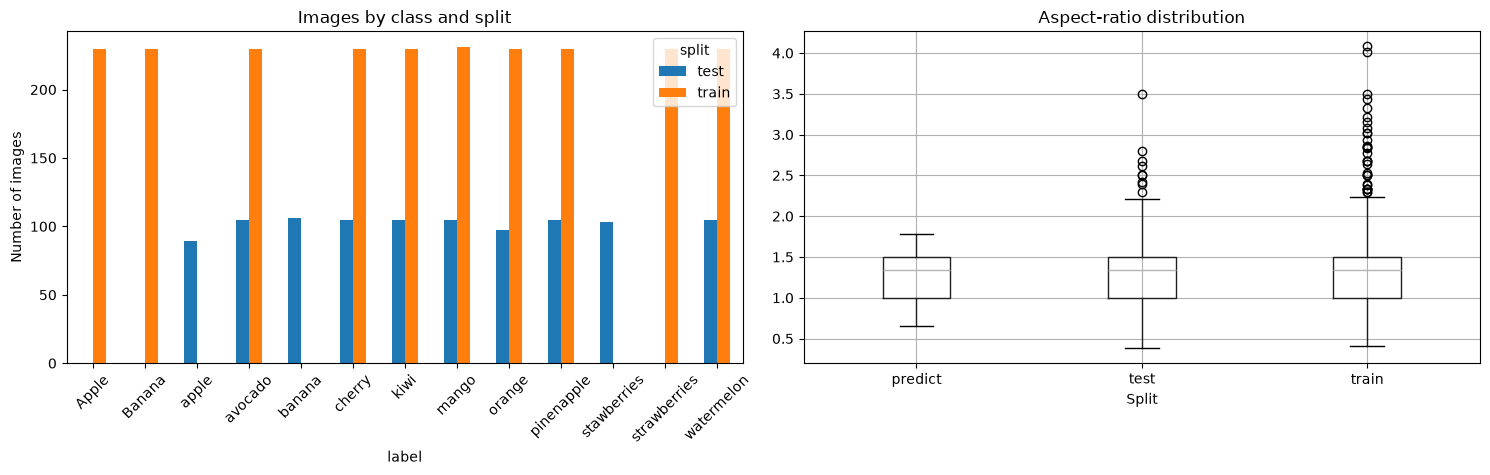

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
counts = images[images['label'].notna()].groupby(['split', 'label']).size().unstack(0, fill_value=0)
counts.plot.bar(ax=axes[0], rot=45, title='Images by class and split')
axes[0].set_ylabel('Number of images')
images.boxplot(column='aspect_ratio', by='split', ax=axes[1])
axes[1].set_title('Aspect-ratio distribution')
axes[1].set_xlabel('Split')
plt.suptitle('')
plt.tight_layout()
plt.show()

## 5. Xem ảnh mẫu của từng lớp

Hiển thị một ảnh mẫu cho mỗi lớp giúp kiểm tra nhanh nhãn có hợp lý không, ảnh có bị sai nội dung rõ ràng không và mức độ đa dạng về góc chụp, nền và hình dạng.

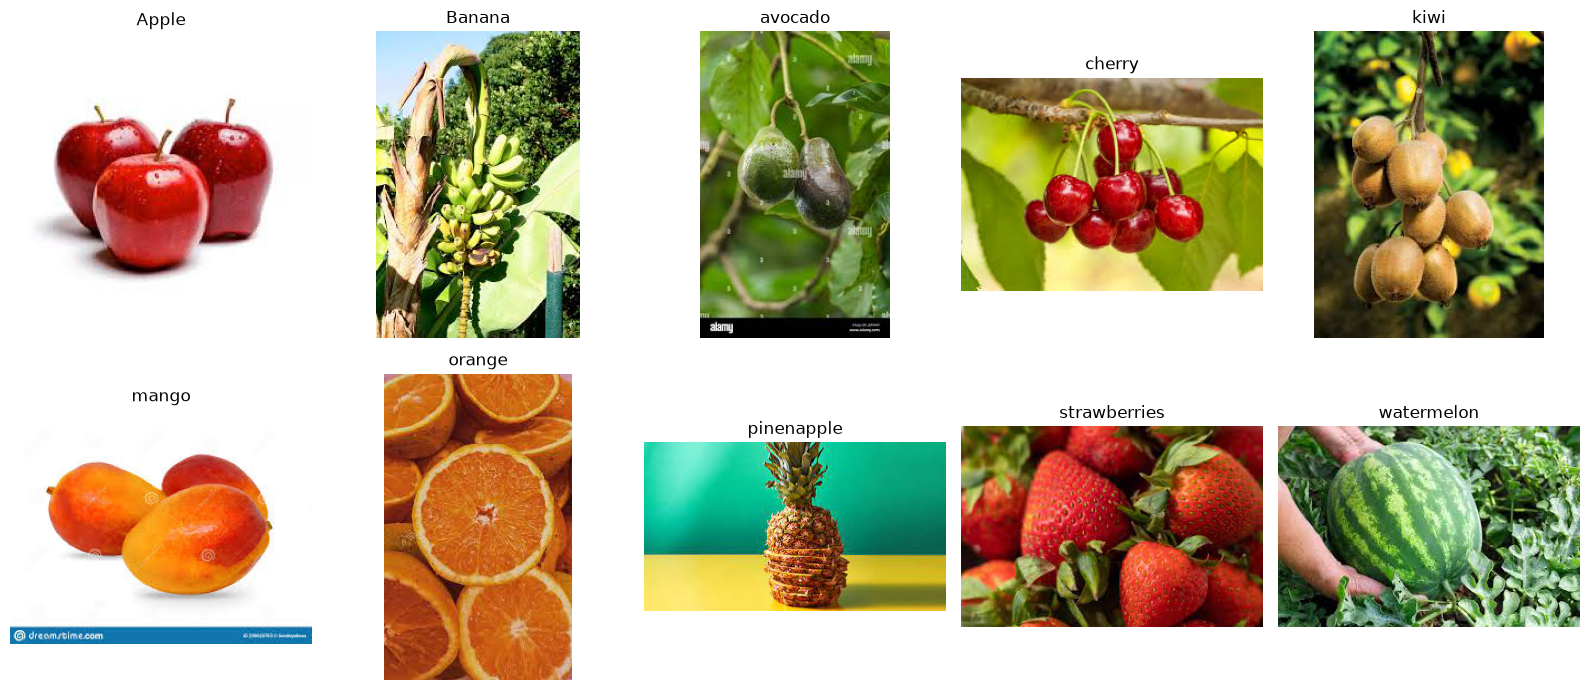

In [6]:
def show_examples(frame):
    labels = sorted(frame['label'].dropna().unique())
    fig, axes = plt.subplots(2, math.ceil(len(labels) / 2), figsize=(16, 7))
    axes = np.asarray(axes).reshape(-1)
    for axis, label in zip(axes, labels):
        row = frame[frame['label'] == label].sample(1, random_state=42).iloc[0]
        with Image.open(row['path']) as image:
            axis.imshow(image.convert('RGB'))
        axis.set_title(label)
        axis.axis('off')
    for axis in axes[len(labels):]:
        axis.axis('off')
    plt.tight_layout()
    plt.show()

show_examples(images[images['split'] == 'train'])

## 6. Kiểm tra ảnh trùng và data leakage

Ảnh có cùng mã băm SHA-256 sau khi chuyển về RGB được xem là trùng nội dung hoàn toàn. Cần phân biệt duplicate trong cùng một split với duplicate giữa train và test. Duplicate giữa train và test có thể làm điểm test cao giả tạo, vì vậy phải xử lý trước khi chốt `data/splits/v1/`.


In [7]:
duplicate_groups = images.groupby('sha256').filter(lambda group: len(group) > 1)
within = duplicate_groups.groupby(['split', 'sha256']).filter(lambda group: len(group) > 1)
cross = duplicate_groups.groupby('sha256').filter(lambda group: group['split'].nunique() > 1)
print(f'Within-split duplicate groups: {within.groupby(["split", "sha256"]).ngroups}')
print(f'Cross-split duplicate groups: {cross.groupby("sha256").ngroups}')
display(cross[['split', 'label', 'relative_path', 'sha256']].sort_values('sha256'))

Within-split duplicate groups: 10
Cross-split duplicate groups: 122


,split,label,relative_path,sha256
1942,train,strawberries,train\strawberries\img_2561.jpeg,01e76f40e5c7fc98c8ee7bae63922b4a3b8ebb60b2ad68...
3129,test,stawberries,test\stawberries\img_1151.jpeg,01e76f40e5c7fc98c8ee7bae63922b4a3b8ebb60b2ad68...
1628,train,pinenapple,train\pinenapple\img_1181.jpeg,033e1e6903674d6e9f8dfe6e6ee6d3b0390d6493936d4f...
3022,test,pinenapple,test\pinenapple\img_1171.jpeg,033e1e6903674d6e9f8dfe6e6ee6d3b0390d6493936d4f...
1805,train,pinenapple,train\pinenapple\img_491.jpeg,05d8907e8debe212e67f7c0505fb95c7a09a10276311ab...
...,...,...,...,...
2356,test,apple,test\apple\img_601.jpeg,fc358a8b63ca1d9526f5223eefe25b8e3ff8c2738620a3...
1621,train,pinenapple,train\pinenapple\img_11.jpeg,fd11dfd2afb14b6e5ba38f84b17ef4946ab9aece6632fb...
3346,predict,None,predict\66.jpeg,fd11dfd2afb14b6e5ba38f84b17ef4946ab9aece6632fb...
121,train,Apple,train\Apple\img_361.jpeg,ffa2470e1993d4410882e7a370897b88a318ec037eadea...


## Findings

- The raw dataset has 2,301 train images, 1,025 test images, and 48 prediction images across 10 fruit classes.
- Train and test have different class counts and inconsistent class spelling/capitalization (`Apple`/`apple`, `Banana`/`banana`, `strawberries`/`stawberries`).
- All inspected files are readable. The dataset contains RGB and palette images, multiple formats, and varied aspect ratios; resizing and channel normalization are required in the shared transform pipeline.
- Exact-content duplicate checks must be resolved before finalizing `data/splits/`: the current raw train/test directories contain cross-split duplicates. This notebook reports them but does not modify `data/raw/`.
